# 05 - Calibration, Uncertainty & Robustness (RQ3)

Runs on **Google Colab (L4 GPU)**. Uses your trained `video_model.pth`.

This notebook answers RQ3 (honest confidence + robustness):
1. **Temperature scaling** - fit on the validation set to calibrate confidence.
2. **ECE + reliability diagram** - before vs after calibration.
3. **Uncertainty flagging** - flag low-confidence clips for human review (risk-coverage).
4. **Cross-match robustness** - accuracy on each held-out match (recording session).

Run cells top to bottom. Saves metrics + figures to Drive.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. In Colab: Runtime > Change runtime type > L4 GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless seaborn gdown

Mounted at /content/drive
Drive ready: True


In [2]:
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
VIDEO_CKPT  = MODELS + '/video_model.pth'
GDRIVE_FILE_ID = ''
EXTRACT_DIR = '/content/data'

NUM_FRAMES = 16
IMG        = 224
BATCH      = 8
SEED       = 42
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

import os
os.makedirs(MODELS, exist_ok=True)
print('Models dir:', MODELS)
print('Loading model from:', VIDEO_CKPT, '-> exists:', os.path.exists(VIDEO_CKPT))

Models dir: /content/drive/MyDrive/BadmintonFYP/model23
Loading model from: /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth -> exists: True


In [3]:
import os, json, glob, zipfile, shutil
import cv2, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms as transforms
from sklearn.model_selection import GroupShuffleSplit
import matplotlib.pyplot as plt, seaborn as sns

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = [z for p in (DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip') for z in glob.glob(p)]
    zips = [z for z in zips if os.path.exists(z)]
    if not zips:
        import gdown
        outp = '/content/DATASET2.zip'
        if not os.path.exists(outp):
            print('Downloading dataset by file ID...')
            gdown.download(id=GDRIVE_FILE_ID, output=outp, quiet=False)
        if os.path.exists(outp) and os.path.getsize(outp) > 1000000:
            zips = [outp]
    if zips:
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('DATASET_DIR =', DATASET_DIR)

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        base = models.resnet18(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b*t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def load_frames(path, n=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames')
    frames = []
    for i in np.linspace(0, total-1, n, dtype=int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < n: frames.append(frames[-1].copy() if frames else np.zeros((IMG,IMG,3),np.uint8))
    return frames[:n]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size/h, size/w); nh, nw = int(h*s), int(w*s)
    r = cv2.resize(img, (nw, nh)); c = np.zeros((size,size,3),np.uint8); y, x = (size-nh)//2, (size-nw)//2; c[y:y+nh, x:x+nw] = r; return c
class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try:
            fr = load_frames(row.file_path)
            t = torch.stack([_norm(torch.from_numpy(letterbox(f).astype(np.float32)/255.0).permute(2,0,1)) for f in fr])
            return t, int(row.label_id)
        except Exception as e:
            return torch.zeros(NUM_FRAMES,3,IMG,IMG), int(row.label_id)
def build_index(rootdir):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(rootdir, folder)
        if not os.path.isdir(p): continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'group_id': gid})
    return pd.DataFrame(rows)
def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val+test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test/(val+test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
print('defs ready')

Device: cuda
DATASET_DIR = /content/data
defs ready


In [4]:
df = build_index(DATASET_DIR)
df_train, df_val, df_test = group_split(df)
print('val', len(df_val), 'test', len(df_test))

model = TemporalPoolingResNet().to(DEVICE)
ck = torch.load(VIDEO_CKPT, map_location=DEVICE)
model.load_state_dict(ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck)
model.eval()
print('loaded', VIDEO_CKPT)

def get_logits(dframe):
    loader = DataLoader(VideoClipDataset(dframe), batch_size=BATCH, num_workers=2)
    Ls, Ys = [], []
    with torch.no_grad():
        for x, y in loader:
            Ls.append(model(x.to(DEVICE)).cpu()); Ys.append(y)
    return torch.cat(Ls), torch.cat(Ys)

print('computing validation logits...')
val_logits, val_labels = get_logits(df_val)
print('computing test logits...')
test_logits, test_labels = get_logits(df_test)
test_groups = df_test.group_id.values
print('done. test_logits', tuple(test_logits.shape))

pred0 = test_logits.argmax(1).numpy(); lab0 = test_labels.numpy()
print()
print('Per-class accuracy of the loaded model:')
for i in range(NUM_CLASSES):
    m = lab0 == i
    if m.sum() > 0:
        print('  %-12s %.3f (n=%d)' % (ID_TO_NAME[i], (pred0[m] == i).mean(), int(m.sum())))
print('Overall: %.4f' % (pred0 == lab0).mean())
print('--> If Overall ~0.94 and Clear healthy = right model.')
print('--> If Overall ~0.79 and Clear ~0.0 = OLD pre-Clear model is on this Drive (see fix).')

val 658 test 732
loaded /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth
computing validation logits...
computing test logits...
done. test_logits (732, 5)

Per-class accuracy of the loaded model:
  Short Serve  0.989 (n=190)
  Lift         0.868 (n=152)
  Clear        0.977 (n=130)
  Drop Shot    0.961 (n=155)
  Smash        0.952 (n=105)
Overall: 0.9508
--> If Overall ~0.94 and Clear healthy = right model.
--> If Overall ~0.79 and Clear ~0.0 = OLD pre-Clear model is on this Drive (see fix).


In [5]:
def softmax_np(logits):
    return F.softmax(logits, dim=1).numpy()
def ece_score(probs, labels, n_bins=15):
    conf = probs.max(1); pred = probs.argmax(1); correct = (pred == labels).astype(float)
    bins = np.linspace(0, 1, n_bins+1); ece = 0.0
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i+1])
        if m.sum() > 0:
            ece += abs(correct[m].mean() - conf[m].mean()) * (m.sum() / len(conf))
    return ece

labels_np = test_labels.numpy()
probs_before = softmax_np(test_logits)
ece_before = ece_score(probs_before, labels_np)
acc_before = (probs_before.argmax(1) == labels_np).mean()

T = torch.ones(1, requires_grad=True)
nll = nn.CrossEntropyLoss()
opt = torch.optim.LBFGS([T], lr=0.05, max_iter=100)
def closure():
    opt.zero_grad(); loss = nll(val_logits / T, val_labels); loss.backward(); return loss
opt.step(closure)
T_opt = float(T.detach().item())

probs_after = softmax_np(test_logits / T_opt)
ece_after = ece_score(probs_after, labels_np)
acc_after = (probs_after.argmax(1) == labels_np).mean()

print('Optimal temperature T = %.3f' % T_opt)
print('Accuracy (temperature scaling does not change it): %.4f -> %.4f' % (acc_before, acc_after))
print('ECE before calibration: %.4f' % ece_before)
print('ECE after  calibration: %.4f' % ece_after)
if ece_after < ece_before:
    print('Calibration improved ECE by %.1f%%' % (100*(ece_before-ece_after)/max(ece_before,1e-9)))

Optimal temperature T = 1.256
Accuracy (temperature scaling does not change it): 0.9508 -> 0.9508
ECE before calibration: 0.0239
ECE after  calibration: 0.0311


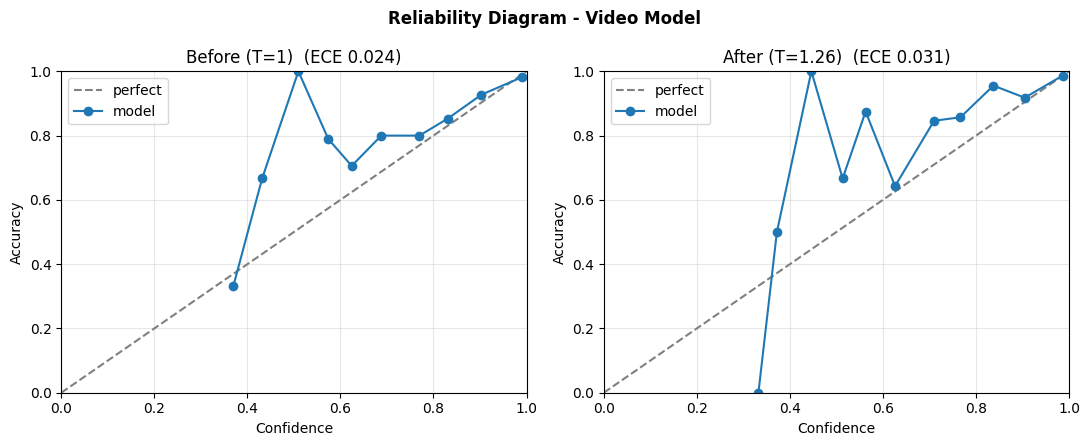

In [6]:
def reliability(probs, labels, n_bins=15):
    conf = probs.max(1); pred = probs.argmax(1); correct = (pred == labels).astype(float)
    bins = np.linspace(0, 1, n_bins+1); xs, ys = [], []
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i+1])
        if m.sum() > 0:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return xs, ys

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, probs, title, ece in [(axes[0], probs_before, 'Before (T=1)', ece_before),
                              (axes[1], probs_after, 'After (T=%.2f)' % T_opt, ece_after)]:
    xs, ys = reliability(probs, labels_np)
    ax.plot([0,1], [0,1], '--', color='gray', label='perfect')
    ax.plot(xs, ys, 'o-', color='C0', label='model')
    ax.set_xlabel('Confidence'); ax.set_ylabel('Accuracy')
    ax.set_title(title + '  (ECE %.3f)' % ece); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('Reliability Diagram - Video Model', fontweight='bold')
plt.tight_layout(); plt.savefig(MODELS + '/calibration_reliability.png', dpi=150); plt.show()

Risk-coverage (using calibrated confidence):
  conf >= 0.50 -> auto-handle 98.5% at 0.954 acc | flag 1.5% for review
  conf >= 0.60 -> auto-handle 94.1% at 0.962 acc | flag 5.9% for review
  conf >= 0.70 -> auto-handle 91.8% at 0.969 acc | flag 8.2% for review
  conf >= 0.80 -> auto-handle 85.7% at 0.978 acc | flag 14.3% for review
  conf >= 0.90 -> auto-handle 76.1% at 0.984 acc | flag 23.9% for review


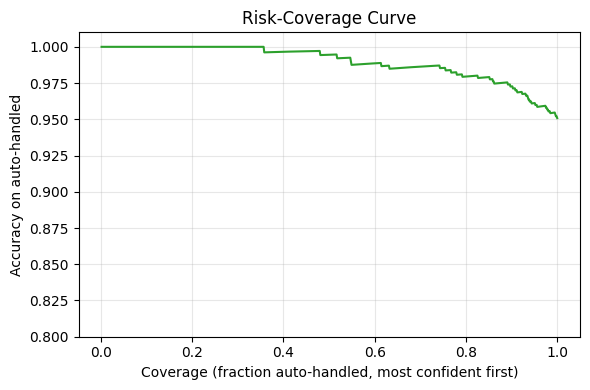

In [7]:
conf_after = probs_after.max(1); pred_after = probs_after.argmax(1); correct = (pred_after == labels_np)

print('Risk-coverage (using calibrated confidence):')
for thr in [0.5, 0.6, 0.7, 0.8, 0.9]:
    keep = conf_after >= thr
    cov = keep.mean()
    acc_kept = correct[keep].mean() if keep.sum() > 0 else float('nan')
    print('  conf >= %.2f -> auto-handle %.1f%% at %.3f acc | flag %.1f%% for review'
          % (thr, 100*cov, acc_kept, 100*(1-cov)))

order = np.argsort(-conf_after)
cov_axis = np.arange(1, len(order)+1) / len(order)
acc_axis = np.cumsum(correct[order].astype(float)) / np.arange(1, len(order)+1)
plt.figure(figsize=(6,4))
plt.plot(cov_axis, acc_axis, color='C2')
plt.xlabel('Coverage (fraction auto-handled, most confident first)')
plt.ylabel('Accuracy on auto-handled')
plt.title('Risk-Coverage Curve'); plt.grid(alpha=0.3); plt.ylim(0.8, 1.01)
plt.tight_layout(); plt.savefig(MODELS + '/calibration_risk_coverage.png', dpi=150); plt.show()

Per-match accuracy on held-out matches (>=5 clips):
                         mean  count
group                               
2022-08-30_18-38-37  0.883117     77
2022-09-07_19-32-45  0.925373     67
2022-09-06_18-09-11  0.927711     83
2022-08-31_18-36-59  0.928058    139
2022-09-07_17-46-41  0.982143     56
2022-08-30_18-27-08  0.982249    169
2022-09-07_19-24-02  0.984848     66
2022-09-06_18-01-58  0.986667     75

Across matches -> mean 0.950 | min 0.883 | max 0.987 | std 0.039


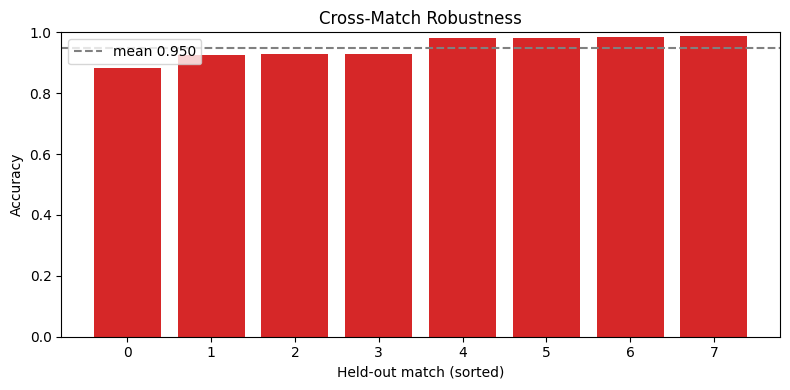

In [8]:
dd = pd.DataFrame({'group': test_groups, 'correct': correct.astype(float)})
per = dd.groupby('group')['correct'].agg(['mean', 'count'])
per = per[per['count'] >= 5].sort_values('mean')
print('Per-match accuracy on held-out matches (>=5 clips):')
print(per)
print()
print('Across matches -> mean %.3f | min %.3f | max %.3f | std %.3f'
      % (per['mean'].mean(), per['mean'].min(), per['mean'].max(), per['mean'].std()))

plt.figure(figsize=(8,4))
plt.bar(range(len(per)), per['mean'].values, color='C3')
plt.axhline(per['mean'].mean(), ls='--', color='gray', label='mean %.3f' % per['mean'].mean())
plt.xlabel('Held-out match (sorted)'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
plt.title('Cross-Match Robustness'); plt.legend()
plt.tight_layout(); plt.savefig(MODELS + '/robustness_per_match.png', dpi=150); plt.show()

In [9]:
out = {
    'temperature': T_opt,
    'accuracy': float(acc_after),
    'ece_before': float(ece_before),
    'ece_after': float(ece_after),
    'per_match_mean': float(per['mean'].mean()),
    'per_match_min': float(per['mean'].min()),
    'per_match_max': float(per['mean'].max()),
    'per_match_std': float(per['mean'].std()),
    'n_test_clips': int(len(labels_np)),
    'n_test_matches': int(len(per)),
}
json.dump(out, open(MODELS + '/calibration_metrics.json', 'w'), indent=2)
print('Saved calibration + robustness metrics and figures to', MODELS)
for k, v in out.items():
    print(' ', k, '=', v)

Saved calibration + robustness metrics and figures to /content/drive/MyDrive/BadmintonFYP/model23
  temperature = 1.2562787532806396
  accuracy = 0.9508196721311475
  ece_before = 0.02386985971627992
  ece_after = 0.031079035476257216
  per_match_mean = 0.9500206180179547
  per_match_min = 0.8831168831168831
  per_match_max = 0.9866666666666667
  per_match_std = 0.03907885722016695
  n_test_clips = 732
  n_test_matches = 8
